# Lab 02 · NumPy for Numerical Computing
**CS-3105 Machine Learning Lab** · Lab Instructor: Engr. Muhammad Awais

**CLO 5** (C-3 Apply, PLO 5 Modern Tool Usage): *Use Python programming and tools to perform data handling and basic operations.*

**Rules:** no Python loops where a NumPy function exists · label every output, e.g. `print("T6b:", ...)` · Runtime → Restart and run all before you submit · push to `ML-Lab-<RollNo>/Lab02/Lab02.ipynb` by **Thursday 29 Oct, 11:59 PM**.

Name: Jawahir Ali<br>
Roll No: 2024-SE-34

### Datasets (run this cell first, do not edit)
- **Census 2023**: Pakistan Bureau of Statistics, 7th Population and Housing Census (provinces, ICT, AJK, GB).
- **Climate**: 1991–2020 climate normals (PMD / WMO) as published in the city climate tables.
- **Inflation**: Pakistan Economic Survey 2024-25, Chapter 7, Fig 7.1 (PBS CPI, year-on-year %).
- **Marks**: sample lab-section marks.

In [1]:
import numpy as np

#  DATASETS (given to students in the starter notebook) 
# D1. Population Census 2023 (PBS), source: 2023 Pakistani census results
units = np.array(["Punjab", "Sindh", "Khyber Pakhtunkhwa", "Balochistan", "Islamabad", "AJK", "Gilgit-Baltistan"])
pop_2023 = np.array([127_688_922, 55_696_147, 40_856_097, 14_894_402, 2_363_863, 4_333_467, 1_709_049])
pop_2017 = np.array([109_989_655, 47_854_510, 35_501_964, 12_335_129, 2_003_368, 4_045_367, 1_492_924])

# D2. Climate normals 1991-2020 (PMD / WMO), mean daily maximum temperature (°C) and rainfall (mm)
cities = np.array(["Lahore", "Karachi", "Islamabad", "Peshawar", "Quetta"])
months = np.array(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
tmax = np.array([
    [18.4, 22.2, 27.5, 34.2, 38.9, 38.9, 35.6, 34.7, 34.4, 32.4, 27.1, 21.4],   # Lahore
    [26.3, 28.7, 32.6, 35.0, 35.7, 35.7, 33.6, 32.5, 33.4, 35.6, 32.6, 28.4],   # Karachi
    [17.7, 20.0, 24.8, 30.6, 36.1, 38.3, 35.4, 33.9, 33.4, 30.9, 25.4, 20.4],   # Islamabad
    [18.1, 20.1, 24.7, 30.6, 36.5, 39.6, 37.4, 35.9, 34.8, 31.0, 25.2, 20.6],   # Peshawar
    [11.8, 14.0, 19.5, 25.9, 31.4, 35.5, 36.8, 35.4, 31.9, 26.0, 19.6, 14.6]])  # Quetta
rain = np.array([
    [21.9, 31.5, 31.5, 19.5, 17.7, 73.8, 188.6, 177.1, 88.6, 10.3, 6.9, 6.8],
    [10.6, 5.5, 3.2, 11.1, 9.2, 24.6, 86.1, 104.7, 44.0, 12.7, 0.7, 5.6],
    [55.2, 93.4, 95.2, 58.1, 39.9, 78.4, 310.6, 317.0, 135.4, 34.4, 17.7, 25.9],
    [39.8, 69.9, 78.2, 68.1, 26.7, 25.4, 69.0, 68.5, 34.8, 26.7, 16.9, 17.3],
    [55.0, 58.4, 49.5, 40.0, 17.8, 3.2, 8.8, 4.9, 4.2, 4.5, 19.3, 34.6]])

# D3. CPI inflation, year-on-year % (Pakistan Economic Survey 2024-25, Fig 7.1, from PBS)
cpi_months = np.array(["Jul", "Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr"])
cpi = np.array([[28.3, 27.4, 31.4, 26.8, 29.2, 29.7, 28.3, 23.1, 20.7, 17.3],    # FY2024
                [11.1,  9.6,  6.9,  7.2,  4.9,  4.1,  2.4,  1.5,  0.7,  0.3]])   # FY2025

# D4. Marks of one lab section (sample class data)
marks = np.array([45, 78, 92, 38, 66, 97, 49, 55, 71, 83])

## Task 1 · Setup
Import NumPy as `np` and print its version.

In [2]:
import numpy as np
print("T1:", np.__version__)

T1: 2.4.6


## Task 2 · Class register: creating arrays
Your lab section has 10 students.
- **(a)** An attendance array of 10 zeros.
- **(b)** A "fee paid" array of 10 ones.
- **(c)** An array giving every student 5 grace marks (10 fives).
- **(d)** Roll numbers 10 to 50 (inclusive).
- **(e)** Only the even roll numbers from 10 to 50.
- **(f)** A 3 × 3 seat map holding the values 0 to 8.
- **(g)** A 3 × 3 identity matrix.

In [19]:
print("T2a:", np.zeros(10))
print("T2b:", np.ones(10))
print("T2c:", np.full(10, 5))
print("T2d:", np.arange(10, 51))
print("T2e:", np.arange(10, 51, 2))
print("T2f:\n", np.arange(9).reshape(3, 3))
print("T2g:\n", np.eye(3))

T2a: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
T2b: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
T2c: [5 5 5 5 5 5 5 5 5 5]
T2d: [10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33
 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50]
T2e: [10 12 14 16 18 20 22 24 26 28 30 32 34 36 38 40 42 44 46 48 50]
T2f:
 [[0 1 2]
 [3 4 5]
 [6 7 8]]
T2g:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


## Task 3 · Randomness and reproducibility
- **(a)** Set `np.random.seed(2026)`, then generate one random number between 0 and 1.
- **(b)** Generate 25 numbers from the standard normal distribution.
- **(c)** Set `np.random.seed(42)` and roll 10,000 Ludo dice with `np.random.randint`. Count each face with `np.unique(..., return_counts=True)`.
- **(d)** Estimate P(six) and compare it with 1/6.
- **(e)** Count how many times two sixes came in a row (no loops).

In [20]:
np.random.seed(2026)
print("T3a:", np.random.rand())
print("T3b:", np.random.randn(25))

np.random.seed(42)
rolls = np.random.randint(1, 7, 10000)          # 7 is exclusive
faces, counts = np.unique(rolls, return_counts=True)
print("T3c:", dict(zip(faces, counts)))

p6 = np.mean(rolls == 6)                         # True/False mean = probability
print("T3d:", p6, "vs", 1/6)

double6 = np.sum((rolls[:-1] == 6) & (rolls[1:] == 6))   # shifted comparison, no loop
print("T3e:", double6)


T3a: 0.21934563492692294
T3b: [ 0.34904966 -0.06370324 -0.04437885 -0.88093025  0.12030048  0.85029072
 -0.69607647  0.99810635 -1.58120639 -0.79589368  2.00615572 -1.78051281
  1.41324558 -0.99029074 -0.31637995 -0.44678319 -1.25614422  0.67975016
 -0.04040287 -0.61953965  0.74720313  0.3595902   0.22039541  1.98726071
 -1.6745924 ]
T3c: {np.int32(1): np.int64(1665), np.int32(2): np.int64(1692), np.int32(3): np.int64(1625), np.int32(4): np.int64(1672), np.int32(5): np.int64(1689), np.int32(6): np.int64(1657)}
T3d: 0.1657 vs 0.16666666666666666
T3e: 265


## Task 4 · Spacing and reshaping
- **(a)** An array from 0.01 to 1.00 in steps of 0.01, reshaped to 10 × 10.
- **(b)** 20 evenly spaced points between 0 and 1.
- **(c)** Reshape Lahore's 12 monthly rainfall values (`rain[0]`) into 4 quarters × 3 months.
- **(d)** Total rain per quarter, and the index of the wettest quarter.

In [5]:
a=np.linspace(0.01,1.00,100).reshape(10,10)
b=np.linspace(0,1,20)
c=rain[0].reshape(4,3)
csum=c.sum(axis=1)
print("T4d: ",csum,np.argmax(csum))

T4d:  [ 84.9 111.  454.3  24. ] 2


## Task 5 · Exam hall seating plan (indexing and slicing)
The exam hall has 25 seats: `hall = np.arange(1, 26).reshape(5, 5)`. Reproduce exactly:
- **(a)** `hall[2:, 1:]`  **(b)** `hall[3, 4]`  **(c)** `hall[0:3, 1:2]`  **(d)** `hall[4]`  **(e)** `hall[3:]`
- **(f)** The sum and standard deviation of all seat numbers.

For each slice, write in a comment which seats the invigilator is pointing at.

In [6]:
hall = np.arange(1, 26).reshape(5, 5)
print("T5:")
print(hall[2:, 1:])   # rows 3-5, columns 2-5 -> seats
print(hall[3, 4])
print(hall[0:3, 1:2])
print(hall[4])
print(hall[3:])
print(hall.sum(), hall.std())

T5:
[[12 13 14 15]
 [17 18 19 20]
 [22 23 24 25]]
20
[[ 2]
 [ 7]
 [12]]
[21 22 23 24 25]
[[16 17 18 19 20]
 [21 22 23 24 25]]
325 7.211102550927978


## Task 6 · Census 2023 (real data, PBS)
Using `units`, `pop_2023` and `pop_2017`:
- **(a)** Total population.
- **(b)** Each unit's share of the total, in %.
- **(c)** The most populous unit.
- **(d)** Units with more than 20 million people.
- **(e)** Annual growth rate 2017–2023 for every unit, in one line: `((pop_2023 / pop_2017) ** (1/6) - 1) * 100`.
- **(f)** The fastest-growing unit.

**Interpret:** in 1–2 lines, what do (e) and (f) say? Compare AJK with the rest.

In [7]:
total = pop_2023.sum()
share = pop_2023 / total * 100
print("T6:")
print(units[np.argmax(pop_2023)])
print(units[pop_2023 > 20_000_000])
growth = ((pop_2023 / pop_2017) ** (1/6) - 1) * 100
print(units[np.argmax(growth)])


T6:
Punjab
['Punjab' 'Sindh' 'Khyber Pakhtunkhwa']
Balochistan


## Task 7 · Climate of five cities (real data, PMD 1991–2020 normals)
Using `tmax` (mean daily maximum °C) and `rain` (mm), rows = `cities`, columns = `months`:
- **(a)** Shape of `tmax`.
- **(b)** Annual mean maximum temperature of each city.
- **(c)** Hottest month of each city (use `argmax` + `months`).
- **(d)** 5-city average for each month.
- **(e)** Number of months above 35 °C in each city.
- **(f)** Lahore's temperatures in °F (`F = C × 9/5 + 32`).
- **(g)** Monsoon (Jul–Sep) rain of each city by slicing columns.
- **(h)** The wettest city in the monsoon, and what % of each city's yearly rain falls in the monsoon.

**Interpret:** in 1–2 lines, which result surprised you, and why?

In [8]:
print("T7:")
print(tmax.shape)
print(tmax.mean(axis=1))                  # (b)
print(months[tmax.argmax(axis=1)])        # (c)
print(tmax.mean(axis=0))                  # (d)
print((tmax > 35).sum(axis=1))            # (e)
print(tmax[0] * 9/5 + 32)                 # (f)
monsoon = rain[:, 6:9].sum(axis=1)        # (g) Jul, Aug, Sep = index 6, 7, 8
print(cities[np.argmax(monsoon)])         # (h)
print(monsoon / rain.sum(axis=1) * 100)

T7:
(5, 12)
[30.475      32.50833333 28.90833333 29.54166667 25.2       ]
['May' 'May' 'Jun' 'Jun' 'Jul']
[18.46 21.   25.82 31.26 35.72 37.6  35.76 34.48 33.58 31.18 25.98 21.08]
[3 3 3 4 3]
[ 65.12  71.96  81.5   93.56 102.02 102.02  96.08  94.46  93.92  90.32
  80.78  70.52]
Islamabad
[67.38356571 73.83647799 60.49793847 31.83077776  5.96269154]


## Task 8 · Inflation FY2024 vs FY2025 (real data, Pakistan Economic Survey 2024-25)
`cpi` has 2 rows (FY2024, FY2025) and 10 columns (Jul to Apr), year-on-year CPI inflation in %.
- **(a)** Average inflation of each year.
- **(b)** FY2024 months with inflation above 25 %.
- **(c)** Drop in inflation for each month (FY2024 − FY2025).
- **(d)** The month with the biggest drop.
- **(e)** Label each FY2025 month "Low" (< 5), "Moderate" (5–10) or "High" (≥ 10) with `np.where`.

**Interpret:** in 1–2 lines, what happened to prices in Pakistan between the two years?

In [9]:
print("T8:")
print(cpi.mean(axis=1))                         # (a)
print(cpi_months[cpi[0] > 25])                  # (b)
drop = cpi[0] - cpi[1]                          # (c)
print(drop, cpi_months[np.argmax(drop)])        # (d)
label = np.where(cpi[1] < 5, "Low",
         np.where(cpi[1] < 10, "Moderate", "High"))   # (e) nested np.where
print(label)


T8:
[26.22  4.87]
['Jul' 'Aug' 'Sep' 'Oct' 'Nov' 'Dec' 'Jan']
[17.2 17.8 24.5 19.6 24.3 25.6 25.9 21.6 20.  17. ] Jan
['High' 'Moderate' 'Moderate' 'Moderate' 'Low' 'Low' 'Low' 'Low' 'Low'
 'Low']


## Task 9 · Grace marks
Using `marks`:
- **(a)** Add 5 grace marks but cap at 100 (`np.clip`).
- **(b)** Pass % (≥ 50) after grace.
- **(c)** Index of students who passed **only because of** the grace marks.
- **(d)** z-score of each student after grace.

In [10]:
print("T9:")

g = np.clip(marks + 5, 0, 100)
print(np.mean(g >= 50) * 100)                          # pass %
only_grace = np.where((marks < 50) & (g >= 50))[0]     # pehle fail, ab pass
print(only_grace)
z = (g - g.mean()) / g.std()
print(z)

T9:
90.0
[0 6]
[-1.17075842  0.56955815  1.30787427 -1.53991648 -0.06328424  1.46608486
 -0.95981095 -0.64338976  0.20040009  0.83324248]


## Task 10 · An image is an array
- **(a)** Start from `np.zeros((8, 8), dtype=int)` and draw the "7" from the lecture with slicing (white = 255, grey = 128).
- **(b)** Flip it left-right.
- **(c)** Invert it (`255 - img`).
- **(d)** Crop rows 1–4 and columns 3–6.
- **(e)** Brighten by 80, capped at 255.
- **(f)** Print its shape, dtype and number of white pixels.

*Optional:* `import matplotlib.pyplot as plt; plt.imshow(img, cmap='gray')`

In [11]:
# (a) making 7 
img = np.zeros((8, 8), dtype=int)
img[1, 1:7]   = 255    #  (row 1, columns 1 to 6)
img[2:7, 5]   = 255    # (rows 2 to 6, column 5)
img[4, 3:7]   = 128    # (row 4, columns 3 to 6)
print("T10a:\n", img)

# (b) left-right flip
print("T10b:\n", img[:, ::-1])        #  np.fliplr(img)

# (c) invert
print("T10c:\n", 255 - img)

# (d) crop: rows 1-4, columns 3-6
print("T10d:\n", img[1:5, 3:7])

# (e) brighten by 80, cap 255
print("T10e:\n", np.clip(img + 80, 0, 255))

# (f) shape, dtype, white pixels
print("T10f:", img.shape, img.dtype, np.sum(img == 255))


T10a:
 [[  0   0   0   0   0   0   0   0]
 [  0 255 255 255 255 255 255   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0 128 128 128 128   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0   0   0   0   0   0]]
T10b:
 [[  0   0   0   0   0   0   0   0]
 [  0 255 255 255 255 255 255   0]
 [  0   0 255   0   0   0   0   0]
 [  0   0 255   0   0   0   0   0]
 [  0 128 128 128 128   0   0   0]
 [  0   0 255   0   0   0   0   0]
 [  0   0 255   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0]]
T10c:
 [[255 255 255 255 255 255 255 255]
 [255   0   0   0   0   0   0 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 127 127 127 127 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 255 255   0 255 255]
 [255 255 255 255 255 255 255 255]]
T10d:
 [[255 255 255 255]
 [  0   0 255   0]
 [  0   0 255   0]
 [128 128 128 128]]
T10e:
 [[ 80  80  80  80  80  80  80  80]
 [ 80 255 

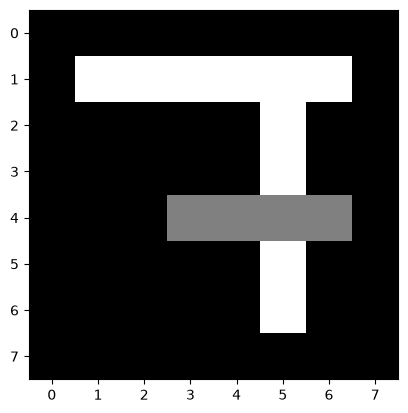

In [12]:
import matplotlib.pyplot as plt
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.show()

## Task 11 · Reflection (Markdown cell)
Write 3–5 sentences: one finding from the census, one from the climate data and one from inflation that you did not know before. Then name one NumPy function that saved you from writing a loop, and what the loop would have looked like.

T11: In the census data, Balochistan grew fastest at about 3.2% per year between 2017 and 2023, while AJK grew slowest at only about 1.1%, far below the other units. In the climate data, I did not expect Karachi to get roughly 74% of its yearly rain in the monsoon months, while Quetta gets only about 6% of its rain then and is wettest in winter and spring
<hr>
In the inflation data, average CPI inflation fell from about 26% in FY2024 to under 5% in FY2025, with the biggest monthly drop (about 26 points) in January.
<hr>
The function that saved me the most work was axis-based aggregation like <b>rain.sum(axis=1)</b>, which gave every city’s total in one line. Without it, I would have written a for loop over the cities and an inner loop over the months, adding each value into a running total.